# **Install & Import**

In [6]:
# @title Install
!pip install git+https://github.com/ComputationalPsychiatry/pyhgf.git
#!pip install numpy
#!pip install jax
#!pip install pandas
#!pip install scipy

  Cloning https://github.com/ComputationalPsychiatry/pyhgf.git to /tmp/pip-req-build-p1rcsyc6
  Running command git clone --filter=blob:none --quiet https://github.com/ComputationalPsychiatry/pyhgf.git /tmp/pip-req-build-p1rcsyc6
  Resolved https://github.com/ComputationalPsychiatry/pyhgf.git to commit d9958ece0a738043ed42eb8b4d966cc362032cf7
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 15.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 619.6/619.6 kB 14.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 39.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 43.7 MB/s  0:00:00
  Created wheel for pyhgf: filename=pyhgf-0.3.3-cp312-abi3-linux_x86_64.whl size=990290 sha256=a25b7b193df3f9e51d1ee71605166021acc17a2b723b738a17f5130ad5fee787
  Stored in dir

In [7]:
# @title Import
from pyhgf import load_data
from pyhgf.model import Network
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider
from ipywidgets import fixed, IntSlider, FloatSlider, interactive, Output
import jax.numpy as jnp
from jax import grad
import pandas as pd
from scipy.special import logit
import scipy.stats as stats
import scipy.integrate as integrate
import math
from IPython.display import clear_output

In [8]:
# @title Coupling function

def g(x):
    return 1/(1 + np.exp(-x))
def g1(x):
    return g(x) * (1 - g(x))
def g2(x):
    return g1(x) * (1-2*g(x))

degree = 1

def g(x:int):
    return np.power(x,degree)

def g1(x:int):
    return degree * np.power(x,degree-1)

def g2(x:int):
    return degree*(degree-1) * np.power(x,degree-2)

In [9]:
# @title Create gHGF
data = np.array([0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0])

hgf = (
    Network()
    .add_nodes(mean=0.5, kind="continuous-state")
    .add_nodes(value_children=0,mean=0.5,tonic_volatility=0)
)
hgf.plot_network()
hgf = hgf.input_data(input_data=data)

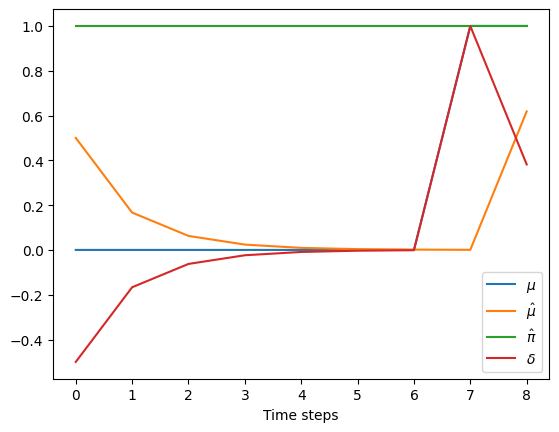

In [10]:
level = 0
plt.plot(hgf.node_trajectories[level]["mean"],label=r"$\mu$")
plt.plot(hgf.node_trajectories[level]["expected_mean"],label=r"$\hat{\mu}$")
plt.plot(hgf.node_trajectories[level]["expected_precision"],label=r"$\hat{\pi}$")
plt.plot(hgf.node_trajectories[level]["temp"]["value_prediction_error"],label=r"$\delta$")
plt.xlabel("Time steps")
plt.legend()

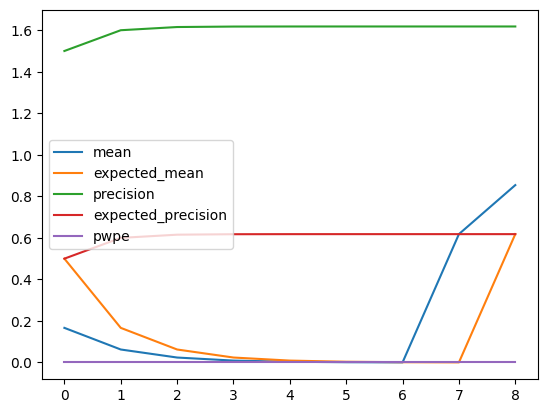

In [11]:
level=1
plt.plot(hgf.node_trajectories[level]["mean"],label="mean")
plt.plot(hgf.node_trajectories[level]["expected_mean"],label="expected_mean")
plt.plot(hgf.node_trajectories[level]["precision"],label="precision")
plt.plot(hgf.node_trajectories[level]["expected_precision"],label="expected_precision")
plt.plot(hgf.node_trajectories[level]["temp"]["value_prediction_error"]*hgf.node_trajectories[0]["expected_precision"]/hgf.node_trajectories[1]["precision"],label="pwpe")
plt.legend()

# **Bogacz Model**

## Exercise 2

In [12]:
def plot_bogacz_ex2(duration_sec:int, time_resolution:float, mean_prior:float, variance_prior:float, mean_evidence:float, variance_evidence:float):

    #attributes = hgf.last_attributes
    duration = int(np.round(duration_sec/time_resolution))

    phi = np.full(duration,float(mean_prior))
    pe_prior = np.zeros(duration) # OR attributes[0]["expected_mean"] - attributes[0]["expected_mean"] which is 0
    pe_evidence = np.zeros(duration) # OR attributes[0]["mean"] - attributes[0]["expected_mean"]

    for i in range(1,duration):
        # Bogacz [13]
        pe_prior[i] = (pe_prior[i-1]
                    + (time_resolution
                        * (phi[i-1] - mean_prior - (variance_prior * pe_prior[i-1]))
                        )
                    )

        # Bogacz [14]
        pe_evidence[i] = (pe_evidence[i-1]
                        + (time_resolution
                            * (mean_evidence - g(phi[i-1]) - (variance_evidence * pe_evidence[i-1]))
                            )
                        )

        # Bogacz [12]
        phi[i] = (phi[i-1]
                + (time_resolution
                    * (pe_evidence[i] * g1(phi[i-1]) - pe_prior[i])
                    )
                )

    plt.figure(figsize=(10, 4))
    plt.suptitle("Belief trajectory of $\phi$")

    plt.plot(phi,label="$\phi$")
    plt.plot(pe_prior,label="$\\varepsilon_p$")
    plt.plot(pe_evidence,label="$\\varepsilon_u$")
    plt.legend()

    print("mean_prior "+str(mean_prior))
    print("mean_evidence "+str(mean_evidence))
    print("variance_prior "+str(variance_prior))
    print("variance_evidence "+str(variance_evidence))
    print("phi max "+ str(phi[np.argmax(phi)])+ " @ " + str(np.argmax(phi)) )
    print("phi end "+str(phi[-1]))
    print("pe_u max "+ str(pe_evidence[np.argmax(pe_evidence)])+ " @ " + str(np.argmax(pe_evidence)) )
    print("pe_u end "+str(pe_evidence[-1]))
    print("pe_p max "+ str(pe_prior[np.argmax(pe_prior)])+ " @ " + str(np.argmax(pe_prior)) )
    print("pe_p end "+str(pe_prior[-1]))
    print()

<>:33: SyntaxWarning: invalid escape sequence '\p'
<>:35: SyntaxWarning: invalid escape sequence '\p'
<>:33: SyntaxWarning: invalid escape sequence '\p'
<>:35: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_812/1388311643.py:33: SyntaxWarning: invalid escape sequence '\p'
  plt.suptitle("Belief trajectory of $\phi$")
/tmp/ipykernel_812/1388311643.py:35: SyntaxWarning: invalid escape sequence '\p'
  plt.plot(phi,label="$\phi$")


mean_prior 3
mean_evidence 2
variance_prior 1
variance_evidence 1
phi max 3.0 @ 0
phi end 2.5438148812626404
pe_u max 0.0 @ 0
pe_u end -0.5067227079513178
pe_p max 0.0 @ 0
pe_p end -0.48654945224901774



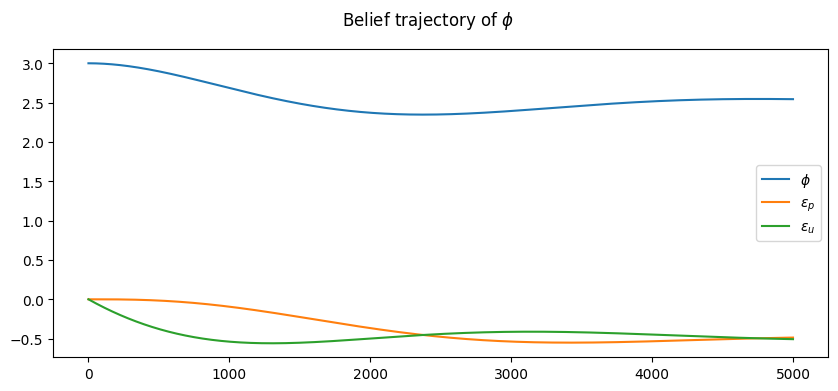

In [13]:
# @title
duration_sec = 5
time_resolution = 0.001

mean_prior = 3#attributes[level]["expected_mean"][0] # (starting point)
mean_evidence = 2#attributes[level]["mean"][0] # (equilibrium point)

variance_prior = 1#hgf.node_trajectories[level]["expected_precision"][0]
variance_evidence = 1#hgf.node_trajectories[level]["precision"][0]

plot_bogacz_ex2(duration_sec=duration_sec, time_resolution=time_resolution, mean_prior=mean_prior, variance_prior=variance_prior, mean_evidence=mean_evidence, variance_evidence=variance_evidence)

## Exercise 5

In [14]:
def plot_bogacz_ex5(level:int, duration_sec:int = 20, time_resolution:float = 0.01, trials:int = 1000, mean_prior:float = 5.0, mean_evidence:float = 5.0, variance_evidence:float = 2.0, variance_evidence_start:float = 1.0):
    duration = int(np.round(duration_sec/time_resolution))
    rng = np.random.default_rng()

    sigma = np.full(trials,variance_evidence_start)
    phi = rng.normal(mean_evidence, np.sqrt(variance_evidence),trials)

    for j in range(1,trials):
        pe_evidence = np.zeros(duration)
        e_evidence = np.zeros(duration)
        for i in range(1,duration):
            # Bogacz [60]
            e_evidence[i] = e_evidence[i-1] + time_resolution * (
                    sigma[j-1] * pe_evidence[i-1] - e_evidence[i-1]
            )

            # Bogacz [59]
            pe_evidence[i] = pe_evidence[i-1] + time_resolution * (
                    phi[j] - mean_prior - e_evidence[i]
            )
        # Bogacz [63]
        sigma[j] = sigma[j-1] + 0.01 * (
                    pe_evidence[-1] * e_evidence[-1] - 1
        )

    plt.figure(figsize=(10, 4))
    plt.suptitle("Sigma trajectory")
    plt.plot(sigma,label="sigma",)
    plt.ylim(0,5)
    plt.legend()

# **cgHGF**

To see the results of the three different model setups, execute the according section with the update equations first and then then "Run cgHGF"


If not stated differently, updates are based on equations from Weber et al. (2025)

### **Update equations (without volatility and precision estimation)**

In [15]:
lambda_value = 0

In [16]:
# @title Continous state nodes
# All equations assume only one child (and only for continous states)
def continuous_state_node_prediction(attributes: dict, time_step: int, node_idx: int, edges):
    # [34 + 36]:
    attributes[node_idx]["expected_mean"][time_step] = attributes[node_idx]["expected_mean"][time_step-1] + attributes[node_idx]["prediction_time_resolution"] * (
                                                       + attributes[node_idx]["lambda"] * attributes[node_idx]["mean"][time_step-1]
                                                       + attributes[node_idx]["tonic_drift"] * attributes[node_idx]["prediction_time_resolution"]
                                                       - attributes[node_idx]["expected_mean"][time_step-1]
    )
    return attributes

def continuous_state_node_posterior_update(attributes: dict, time_step: int, node_idx: int, edges):
    # eLife [39] linear coupling
    attributes[node_idx]["mean"][time_step] = attributes[node_idx]["mean"][time_step-1] + attributes[node_idx]["update_time_resolution"] * (
                                              attributes[node_idx]["expected_mean"][time_step-1]
                                              + attributes[node_idx-1]["expected_precision"][time_step-1] * attributes[node_idx-1]["pe"][time_step-1] / attributes[node_idx]["precision"][time_step-1] # precision-weighted PE
                                              - attributes[node_idx]["mean"][time_step-1]
    )
    return attributes

def continuous_state_node_prediction_error(attributes: dict, time_step: int, node_idx: int, edges):
    # Weber (2020) [4.47]
    attributes[node_idx]["pe"][time_step] = attributes[node_idx]["pe"][time_step-1] + attributes[node_idx]["pe_time_resolution"] * (
                                            attributes[node_idx]["mean"][time_step]
                                            - attributes[node_idx]["expected_mean"][time_step-1]
                                            - attributes[node_idx]["pe"][time_step-1]
    )

    return attributes


In [17]:
# @title Continous-input nodes
def continous_input_node_prediction(attributes: dict, time_step: int, node_idx: int, edges):
    # based on [64]
    attributes[node_idx]["expected_mean"][time_step] = attributes[node_idx]["expected_mean"][time_step-1] + attributes[node_idx]["prediction_time_resolution"] * (
                                                        attributes[node_idx+1]["expected_mean"][time_step-1]
                                                        - attributes[node_idx]["expected_mean"][time_step-1]
    )

    return attributes

def continous_input_node_prediction_error(attributes: dict, time_step: int, node_idx: int, edges):

    attributes[node_idx]["pe"][time_step] = attributes[node_idx]["pe"][time_step-1] + attributes[node_idx]["pe_time_resolution"] * (
                                            (attributes[node_idx]["mean"][time_step-1] - attributes[node_idx]["expected_mean"][time_step-1])
                                            - attributes[node_idx]["pe"][time_step-1]
    )

    # based on  [ 86]
    attributes[node_idx]["precision_weighted_pe"][time_step] = attributes[node_idx]["expected_precision"][time_step-1] * attributes[node_idx]["pe"][time_step] / attributes[node_idx+1]["precision"][time_step-1]

    return attributes

### **Update equations (without volatility estimation)**

In [18]:
lambda_value = 0

In [19]:
# @title Continous state nodes
# All equations assume only one child (and only for continous states)
def continuous_state_node_prediction(attributes: dict, time_step: int, node_idx: int, edges):
    # Collect parents means
    #value_parents_idxs = edges[node_idx].value_parents
    #parent_mean = 0
    #if value_parents_idxs is not None:
    #    for parent_idx, coupling in zip(
    #        value_parents_idxs,
    #        hgf.last_attributes[node_idx]["value_coupling_parents"],
    #    ):
    #        parent_mean += coupling * g(attributes[parent_idx]["mean"][time_step-1])

    # [34 + 36]:
    attributes[node_idx]["expected_mean"][time_step] = attributes[node_idx]["expected_mean"][time_step-1] + attributes[node_idx]["prediction_time_resolution"] * (
                                                       + attributes[node_idx]["lambda"] * attributes[node_idx]["mean"][time_step-1]
                                                       + attributes[node_idx]["tonic_drift"] * attributes[node_idx]["prediction_time_resolution"]
                                                       - attributes[node_idx]["expected_mean"][time_step-1]
    )

    # Weber (2020) [4.73]
    attributes[node_idx]["v"][time_step] = attributes[node_idx]["v"][time_step-1] + attributes[node_idx]["prediction_time_resolution"] * (
                                            np.exp(attributes[node_idx]["tonic_volatility"])
                                            #* np.exp(attributes[node_idx]["internal_volatility_coupling"] * attributes[node_idx]["vol_mean"][time_step-1])
                                            - attributes[node_idx]["v"][time_step-1]
    )

    # Weber (2020) [4.65]
    attributes[node_idx]["p1"][time_step] = attributes[node_idx]["p1"][time_step-1] + attributes[node_idx]["prediction_time_resolution"] * (
                                             + attributes[node_idx]["expected_precision"][time_step-1]
                                             - attributes[node_idx]["precision"][time_step-1] * attributes[node_idx]["p1"][time_step-1]
    )

    # Weber (2020) [4.72]
    attributes[node_idx]["p2"][time_step] = attributes[node_idx]["p2"][time_step-1] + attributes[node_idx]["prediction_time_resolution"] * (
                                             + attributes[node_idx]["v"][time_step] * attributes[node_idx]["expected_precision"][time_step-1]
                                             - attributes[node_idx]["p2"][time_step-1]
    )

    # Weber (2020) [4.67]
    attributes[node_idx]["expected_precision"][time_step] = attributes[node_idx]["expected_precision"][time_step-1] + attributes[node_idx]["prediction_time_resolution"] * (
                                                             + 1
                                                             - attributes[node_idx]["p1"][time_step]
                                                             - attributes[node_idx]["p2"][time_step]
    )

    attributes[node_idx]["expected_precision"][time_step] = np.maximum(
                                                            attributes[node_idx]["expected_precision"][time_step],
                                                            float(attributes[node_idx]["min_precision"])
    )

    return attributes

def continuous_state_node_posterior_update(attributes: dict, time_step: int, node_idx: int, edges):
    ### Value-related nodes
    if edges[node_idx].value_children is not None: # If value-child exists
        child_idx = edges[node_idx].value_children[0]
        coupling = hgf.last_attributes[node_idx]["value_coupling_children"][0]

        # [38] linear coupling
        posterior_precision = attributes[node_idx]["precision"][time_step-1] + attributes[node_idx]["update_time_resolution"] * (
                              + attributes[node_idx]["expected_precision"][time_step-1]
                              + (coupling)**2 / attributes[child_idx]["expected_precision"][time_step-1]
                              - attributes[node_idx]["precision"][time_step-1]
        )
        # [50] non-linear coupling
        #posterior_precision = attributes[node_idx]["precision"][time_step-1] + attributes[node_idx]["update_time_resolution"] * (
        #                      + attributes[node_idx]["expected_precision"][time_step-1]
        #                      + attributes[child_idx]["expected_precision"][time_step-1]
        #                      * ((coupling**2 * g1(attributes[node_idx]["mean"][time_step-1])) - (coupling * g2(attributes[node_idx]["mean"][time_step-1]) * attributes[child_idx]["pe"][time_step-1]))
        #                      - attributes[node_idx]["precision"][time_step-1]
        #)

        attributes[node_idx]["precision"][time_step] = np.maximum(
                                                      posterior_precision,
                                                      float(attributes[node_idx]["min_precision"])
        )

        # [39] linear coupling
        attributes[node_idx]["mean"][time_step] = attributes[node_idx]["mean"][time_step-1] + attributes[node_idx]["update_time_resolution"] * (
                                                  attributes[node_idx]["expected_mean"][time_step-1]
                                                  + attributes[node_idx-1]["expected_precision"][time_step-1] * attributes[node_idx-1]["pe"][time_step-1] / attributes[node_idx]["precision"][time_step-1] # precision-weighted PE
                                                  - attributes[node_idx]["mean"][time_step-1]
        )

        # [51] non-linear coupling
        #attributes[node_idx]["mean"][time_step] = attributes[node_idx]["mean"][time_step-1] + attributes[node_idx]["update_time_resolution"] * (
        #                                          attributes[node_idx]["expected_mean"][time_step-1]
        #                                          + coupling *g1(attributes[node_idx]["mean"][time_step-1]) * attributes[child_idx]["precision_weighted_pe"][time_step-1]
        #                                          - attributes[node_idx]["mean"][time_step-1]
        #)



    return attributes

def continuous_state_node_prediction_error(attributes: dict, time_step: int, node_idx: int, edges):
    # Weber (2020) [4.47]
    attributes[node_idx]["pe"][time_step] = attributes[node_idx]["pe"][time_step-1] + attributes[node_idx]["pe_time_resolution"] * (
                                            attributes[node_idx]["mean"][time_step]
                                            - attributes[node_idx]["expected_mean"][time_step-1]
                                            - attributes[node_idx]["pe"][time_step-1]
    )

    # if parent exists
    if hgf.edges[node_idx].value_parents is not None or edges[node_idx].volatility_parents is not None:
        # Weber (2020) [4.49]
        attributes[node_idx]["precision_weighted_pe"][time_step] = attributes[node_idx]["precision_weighted_pe"][time_step-1] + attributes[node_idx]["pe_time_resolution"] * (
                                                                  + attributes[node_idx]["mean"][time_step]
                                                                  - attributes[node_idx]["expected_mean"][time_step-1]
                                                                  - (attributes[node_idx + 1]["precision"][time_step-1] / (attributes[node_idx]["expected_precision"][time_step-1] * hgf.attributes[node_idx]["value_coupling_parents"][0]))
                                                                  * attributes[node_idx]["precision_weighted_pe"][time_step-1]

        )

    return attributes


In [20]:
# @title Continous-input nodes
def continous_input_node_prediction(attributes: dict, time_step: int, node_idx: int, edges):
    # [64]
    attributes[node_idx]["expected_mean"][time_step] = attributes[node_idx]["expected_mean"][time_step-1] + attributes[node_idx]["prediction_time_resolution"] * (
                                                        attributes[node_idx+1]["expected_mean"][time_step-1]
                                                        - attributes[node_idx]["expected_mean"][time_step-1]
    )

    return attributes

def continous_input_node_prediction_error(attributes: dict, time_step: int, node_idx: int, edges):

    attributes[node_idx]["pe"][time_step] = attributes[node_idx]["pe"][time_step-1] + attributes[node_idx]["pe_time_resolution"] * (
                                            (attributes[node_idx]["mean"][time_step-1] - attributes[node_idx]["expected_mean"][time_step-1])
                                            - attributes[node_idx]["pe"][time_step-1]
    )

    # [70]
    attributes[node_idx]["precision_weighted_pe"][time_step] = (attributes[node_idx]["expected_precision"][time_step-1]
                                                                * attributes[node_idx]["pe"][time_step] / attributes[node_idx+1]["precision"][time_step-1]
                                                                )

    return attributes

### **Update equations & gHGF control model (with internal volatility estimation)**

In [21]:
lambda_value = 1

In [22]:
# @title Create gHGF

data = np.array([0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0])

hgf = (
    Network()
    .add_nodes(mean=0.5, kind="continuous-state")
    .add_nodes(value_children=0,mean=0.5,tonic_volatility=0)
    .add_nodes(volatility_children=1,tonic_volatility=0)
)
hgf = hgf.input_data(input_data=data)

In [23]:
# @title Continous state node
# All equations assume only one child (and only for continous states)
def continuous_state_node_prediction(attributes: dict, time_step: int, node_idx: int, edges):

    # Collect parents means
    value_parents_idxs = edges[node_idx].value_parents
    parent_mean_sum_g = 0
    parent_mean_sum = 0
    if value_parents_idxs is not None:
        for parent_idx, coupling in zip(
            value_parents_idxs,
            hgf.last_attributes[node_idx]["value_coupling_parents"],
        ):
            parent_mean_sum_g += coupling * g(attributes[parent_idx]["mean"][time_step-1])
            parent_mean_sum += coupling * attributes[parent_idx]["mean"][time_step-1]

    # [34 + 36]:
    attributes[node_idx]["expected_mean"][time_step] = attributes[node_idx]["expected_mean"][time_step-1] + attributes[node_idx]["prediction_time_resolution"] * (
                                                       + attributes[node_idx]["lambda"] * attributes[node_idx]["mean"][time_step-1]
                                                       + attributes[node_idx]["prediction_time_resolution"] * (attributes[node_idx]["tonic_drift"] + parent_mean_sum)
                                                       - attributes[node_idx]["expected_mean"][time_step-1]
    )

    # Weber (2020) [4.73]
    attributes[node_idx]["v"][time_step] = attributes[node_idx]["v"][time_step-1] + attributes[node_idx]["prediction_time_resolution"] * (
                                            np.exp(attributes[node_idx]["tonic_volatility"])
                                            * np.exp(attributes[node_idx]["internal_volatility_coupling"] * attributes[node_idx]["vol_mean"][time_step-1])
                                            - attributes[node_idx]["v"][time_step-1]
    )

    # Weber (2020) [4.65]
    attributes[node_idx]["p1"][time_step] = attributes[node_idx]["p1"][time_step-1] + attributes[node_idx]["prediction_time_resolution"] * (
                                             + attributes[node_idx]["expected_precision"][time_step-1]
                                             - attributes[node_idx]["precision"][time_step-1] * attributes[node_idx]["p1"][time_step-1]
    )

    # Weber (2020) [4.72]
    attributes[node_idx]["p2"][time_step] = attributes[node_idx]["p2"][time_step-1] + attributes[node_idx]["prediction_time_resolution"] * (
                                             + attributes[node_idx]["v"][time_step] * attributes[node_idx]["expected_precision"][time_step-1]
                                             - attributes[node_idx]["p2"][time_step-1]
    )

    # Weber (2020) [4.67]
    attributes[node_idx]["expected_precision"][time_step] = attributes[node_idx]["expected_precision"][time_step-1] + attributes[node_idx]["prediction_time_resolution"] * (
                                                             + 1
                                                             - attributes[node_idx]["p1"][time_step]
                                                             - attributes[node_idx]["p2"][time_step]
    )

    attributes[node_idx]["expected_precision"][time_step] = np.maximum(
                                                            attributes[node_idx]["expected_precision"][time_step],
                                                            float(attributes[node_idx]["min_precision"])
    )
    # Weber (2020) [4.90]
    attributes[node_idx]["vol_expected_mean"][time_step] = attributes[node_idx]["vol_expected_mean"][time_step-1] + attributes[node_idx]["prediction_time_resolution"] * (
                                                             + attributes[node_idx]["vol_pe"][time_step-1]
                                                             + parent_mean_sum
    )
    # Weber (2020) [4.93]
    attributes[node_idx]["vol_p1"][time_step] = attributes[node_idx]["vol_p1"][time_step-1] + attributes[node_idx]["prediction_time_resolution"] * (
                                                + attributes[node_idx]["vol_expected_precision"][time_step-1]
                                                - attributes[node_idx]["vol_precision"][time_step-1] * attributes[node_idx]["vol_p1"][time_step-1]
    )
    # Weber (2020) [4.92]
    attributes[node_idx]["vol_expected_precision"][time_step] = attributes[node_idx]["vol_expected_precision"][time_step-1] + attributes[node_idx]["prediction_time_resolution"] * (
                                                             + 1
                                                             - attributes[node_idx]["vol_p1"][time_step]
                                                             - attributes[node_idx]["vol_expected_precision"][time_step-1] * np.exp(attributes[node_idx]["tonic_volatility"])
    )
    return attributes

def continuous_state_node_posterior_update(attributes: dict, time_step: int, node_idx: int, edges):
    ### Value-related nodes

    if edges[node_idx].value_children is not None: # If value-child exists
        child_idx = edges[node_idx].value_children[0]
        coupling = hgf.last_attributes[node_idx]["value_coupling_children"][0]

        # [38] linear coupling
        posterior_precision = attributes[node_idx]["precision"][time_step-1] + attributes[node_idx]["update_time_resolution"] * (
                              + attributes[node_idx]["expected_precision"][time_step-1]
                              + (coupling)**2 / attributes[child_idx]["expected_precision"][time_step-1]
                              - attributes[node_idx]["precision"][time_step-1]
        )
        # [50] non-linear coupling
        #posterior_precision = attributes[node_idx]["precision"][time_step-1] + attributes[node_idx]["update_time_resolution"] * (
        #                      + attributes[node_idx]["expected_precision"][time_step-1]
        #                      + attributes[child_idx]["expected_precision"][time_step-1]
        #                      * ((coupling**2 * g1(attributes[node_idx]["mean"][time_step-1])) - (coupling * g2(attributes[node_idx]["mean"][time_step-1]) * attributes[child_idx]["pe"][time_step-1]))
        #                      - attributes[node_idx]["precision"][time_step-1]
        #)

        attributes[node_idx]["precision"][time_step] = np.maximum(
                                                      posterior_precision,
                                                      float(attributes[node_idx]["min_precision"])
        )

        # [39] linear coupling
        attributes[node_idx]["mean"][time_step] = attributes[node_idx]["mean"][time_step-1] + attributes[node_idx]["update_time_resolution"] * (
                                                  attributes[node_idx]["expected_mean"][time_step-1]
                                                  + attributes[node_idx-1]["expected_precision"][time_step-1] * attributes[node_idx-1]["pe"][time_step-1] / attributes[node_idx]["precision"][time_step-1] # precision-weighted PE
                                                  - attributes[node_idx]["mean"][time_step-1]
        )

        # [51] non-linear coupling
        #attributes[node_idx]["mean"][time_step] = attributes[node_idx]["mean"][time_step-1] + attributes[node_idx]["update_time_resolution"] * (
        #                                          attributes[node_idx]["expected_mean"][time_step-1]
        #                                          + coupling *g1(attributes[node_idx]["mean"][time_step-1]) * attributes[child_idx]["precision_weighted_pe"][time_step-1]
        #                                          - attributes[node_idx]["mean"][time_step-1]
        #)


    ### Volatility-related nodes

    # [43 + 37 without parent] equal to Weber (2020) [4.77]
    attributes[node_idx]["gamma"][time_step] = attributes[node_idx]["gamma"][time_step-1] + attributes[node_idx]["update_time_resolution"] * (
                                               attributes[node_idx]["v"][time_step-1]
                                               * attributes[node_idx]["expected_precision"][time_step-1]
                                               - attributes[node_idx]["gamma"][time_step-1]
    )

    # [44]
    attributes[node_idx]["vol_precision"][time_step] =  attributes[node_idx]["vol_precision"][time_step-1] + attributes[node_idx]["update_time_resolution"]  * (
                                                        attributes[node_idx]["vol_expected_precision"][time_step-1]
                                                        + 0.5 * (attributes[node_idx]["internal_volatility_coupling"] * attributes[node_idx]["gamma"][time_step])**2
                                                        + (attributes[node_idx]["internal_volatility_coupling"] * attributes[node_idx]["gamma"][time_step])**2 * attributes[node_idx]["vope"][time_step-1]
                                                        - (0.5 * attributes[node_idx]["internal_volatility_coupling"]**2 * attributes[node_idx]["gamma"][time_step]) * attributes[node_idx]["vope"][time_step-1]
                                                        - attributes[node_idx]["vol_precision"][time_step-1]
    )
    attributes[node_idx]["vol_precision"][time_step] = np.maximum(
                                                            attributes[node_idx]["vol_precision"][time_step],
                                                            float(attributes[node_idx]["min_precision"])
    )
    # [45]
    attributes[node_idx]["vol_mean"][time_step] = attributes[node_idx]["vol_mean"][time_step-1] + attributes[node_idx]["update_time_resolution"] * (
                                                  attributes[node_idx]["vol_expected_mean"][time_step-1]
                                                  + (0.5 * attributes[node_idx]["internal_volatility_coupling"] * attributes[node_idx]["gamma"][time_step] * attributes[node_idx]["vope"][time_step-1]) / attributes[node_idx]["vol_precision"][time_step]
                                                  - attributes[node_idx]["vol_mean"][time_step-1]
    )
    return attributes

def continuous_state_node_prediction_error(attributes: dict, time_step: int, node_idx: int, edges):
    # Weber (2020) [4.47]
    attributes[node_idx]["pe"][time_step] = attributes[node_idx]["pe"][time_step-1] + attributes[node_idx]["pe_time_resolution"] * (
                                            attributes[node_idx]["mean"][time_step]
                                            - attributes[node_idx]["expected_mean"][time_step-1]
                                            - attributes[node_idx]["pe"][time_step-1]
    )

    # If parent exists, compute precision weighted errors
    if node_idx+1 in attributes:
        # Weber (2020) [4.49]
        attributes[node_idx]["precision_weighted_pe"][time_step] = attributes[node_idx]["precision_weighted_pe"][time_step-1] + attributes[node_idx]["pe_time_resolution"] * (
                                                                  + attributes[node_idx]["mean"][time_step]
                                                                  - attributes[node_idx]["expected_mean"][time_step-1]
                                                                  - (attributes[node_idx + 1]["precision"][time_step-1] / (attributes[node_idx]["expected_precision"][time_step-1] * hgf.attributes[node_idx]["value_coupling_parents"][0]))
                                                                  * attributes[node_idx]["precision_weighted_pe"][time_step-1]

        )
        # [missing] but since placement in network is same as "precision_weighted_pe" we can use those formulas and adjust
        attributes[node_idx]["vol_precision_weighted_pe"][time_step] = attributes[node_idx]["precision_weighted_pe"][time_step-1] + attributes[node_idx]["pe_time_resolution"] * (
                                                                  + attributes[node_idx]["mean"][time_step]
                                                                  - attributes[node_idx]["expected_mean"][time_step-1]
                                                                  - (attributes[node_idx + 1]["precision"][time_step-1] / (attributes[node_idx]["expected_precision"][time_step-1] * hgf.edges[node_idx]["value_parent_coupling"]))
                                                                  * attributes[node_idx]["vol_precision_weighted_pe"][time_step-1]

        )

    # [missing] but since placement in network is same as "pe" I use those formulas and adjust
    attributes[node_idx]["vol_pe"][time_step] = attributes[node_idx]["vol_pe"][time_step-1] + attributes[node_idx]["pe_time_resolution"] * (
                                                attributes[node_idx]["vol_mean"][time_step]
                                                - attributes[node_idx]["vol_expected_mean"][time_step-1]
                                                - attributes[node_idx]["vol_pe"][time_step-1]

    )

    # [48]
    attributes[node_idx]["vope"][time_step] = attributes[node_idx]["vope"][time_step-1] + attributes[node_idx]["pe_time_resolution"] * (
                                               attributes[node_idx]["expected_precision"][time_step-1] / attributes[node_idx]["precision"][time_step]
                                               + attributes[node_idx]["expected_precision"][time_step-1] * attributes[node_idx]["pe"][time_step]**2
                                               - 1
                                               - attributes[node_idx]["vope"][time_step-1]
    )

    # Weber (2020) [4.79]
    attributes[node_idx]["precision_weighted_vope"][time_step] = attributes[node_idx]["precision_weighted_vope"][time_step-1] + attributes[node_idx]["pe_time_resolution"] * (
                                           attributes[node_idx]["vope"][time_step]
                                           * (0.5 * attributes[node_idx]["internal_volatility_coupling"] * attributes[node_idx]["gamma"][time_step]) / attributes[node_idx]["vol_precision"][time_step]
                                           - attributes[node_idx]["precision_weighted_vope"][time_step-1]
    )

    return attributes

In [24]:
# @title Continous input nodes
def continous_input_node_prediction(attributes: dict, time_step: int, node_idx: int, edges):
    # [64]
    attributes[node_idx]["expected_mean"][time_step] = attributes[node_idx]["expected_mean"][time_step-1] + attributes[node_idx]["prediction_time_resolution"] * (
                                                        attributes[node_idx+1]["expected_mean"][time_step-1]
                                                        - attributes[node_idx]["expected_mean"][time_step-1]
    )

    return attributes

def continous_input_node_prediction_error(attributes: dict, time_step: int, node_idx: int, edges):
    #
    attributes[node_idx]["pe"][time_step] = attributes[node_idx]["pe"][time_step-1] + attributes[node_idx]["pe_time_resolution"] * (
                                            (attributes[node_idx]["mean"][time_step-1] - attributes[node_idx]["expected_mean"][time_step-1])
                                            - attributes[node_idx]["pe"][time_step-1]
    )
    # [70]
    attributes[node_idx]["precision_weighted_pe"][time_step] = (attributes[node_idx]["expected_precision"][time_step-1]
                                                                * attributes[node_idx]["pe"][time_step] / attributes[node_idx+1]["precision"][time_step-1]
                                                                )

    return attributes

### **Run cgHGF**

In [25]:
# @title Build belief propagation sequence
update_sequence = []
prediction_sequence = []
indexes=[]

for key, value in hgf.attributes.items():
    if key >= 0:
        indexes.append(key)

# 1. Update and PE steps (Top-down)
for idx in indexes:
    # Check whether node is the input node
    if idx != 0:
        update_sequence.append((idx,continuous_state_node_posterior_update))
        update_sequence.append((idx,continuous_state_node_prediction_error))
    else:
        update_sequence.append((idx, continous_input_node_prediction_error))

# 2. Prediction steps (Bottom-up)
indexes.reverse()
for idx in indexes:
    if idx != 0:
        prediction_sequence.append((idx, continuous_state_node_prediction))
    else:
        update_sequence.append((idx, continous_input_node_prediction))

In [26]:
# @title Compare my sequence with the original one
print("cgHGF prediction sequence: "+str(prediction_sequence))
print("gHGF prediction sequence: "+str(hgf.update_sequence.prediction_steps))
print()
print("cgHGF update sequence: "+str(update_sequence))
print("gHGF update sequence: "+str(hgf.update_sequence.update_steps))

cgHGF prediction sequence: [(2, <function continuous_state_node_prediction at 0x7d5ab817b560>), (1, <function continuous_state_node_prediction at 0x7d5ab817b560>)]
gHGF prediction sequence: ((2, <PjitFunction of <function continuous_node_prediction at 0x7d5ae4a48a40>>), (1, <PjitFunction of <function continuous_node_prediction at 0x7d5ae4a48a40>>), (0, <PjitFunction of <function continuous_node_prediction at 0x7d5ae4a48a40>>))

cgHGF update sequence: [(0, <function continous_input_node_prediction_error at 0x7d5ab817a7a0>), (1, <function continuous_state_node_posterior_update at 0x7d5ab817b2e0>), (1, <function continuous_state_node_prediction_error at 0x7d5ab817b7e0>), (2, <function continuous_state_node_posterior_update at 0x7d5ab817b2e0>), (2, <function continuous_state_node_prediction_error at 0x7d5ab817b7e0>), (0, <function continous_input_node_prediction at 0x7d5ab817b240>)]
gHGF update sequence: ((0, <PjitFunction of <function continuous_node_prediction_error at 0x7d5ae4a3ce00>>),

In [27]:
# @title Simulation method
def cgHGF(duration:int,
          start_attributes=None):

    attributes = {}
    # Create trajectory-arrays for the all parameters of each node
    for level in start_attributes.keys(): # has to be top to bottom

        # Setting initial values on all levels, use given parameters for binary node, in every other case get values from the gHGF
        pe_time_resolution = (
            start_attributes[level]["pe_time_resolution"]
            if level in start_attributes and "pe_time_resolution" in start_attributes[level]
            else time_resolution
        )
        prediction_time_resolution = (
            start_attributes[level]["prediction_time_resolution"]
            if level in start_attributes and "prediction_time_resolution" in start_attributes[level]
            else time_resolution
        )
        update_time_resolution = (
            start_attributes[level]["update_time_resolution"]
            if level in start_attributes and "update_time_resolution" in start_attributes[level]
            else time_resolution
        )
        internal_volatility_coupling = (
            start_attributes[level]["internal_volatility_coupling"]
            if level in start_attributes and "internal_volatility_coupling" in start_attributes[level]
            else 1
        )
        tonic_drift = (
            start_attributes[level]["tonic_drift"]
            if level in start_attributes and "tonic_drift" in start_attributes[level]
            else (hgf.last_attributes[level]["tonic_drift"]
                  if "tonic_drift" in hgf.last_attributes[level]
                  else 0)
        )
        tonic_volatility = (
            start_attributes[level]["tonic_volatility"]
            if level in start_attributes and "tonic_volatility" in start_attributes[level]
            else (hgf.last_attributes[level]["tonic_volatility"]
                  if "tonic_volatility" in hgf.last_attributes[level]
                  else 0)
        )
        lambda_value = (
            start_attributes[level]["lambda"]
            if level in start_attributes and "lambda" in start_attributes[level]
            else (hgf.last_attributes[level]["temp"]["autoconnection_strength"]
                  if "temp" in hgf.last_attributes[level] and "autoconnection_strength" in hgf.last_attributes[level]["temp"]
                  else 1)
        )

        # (Some formulas here are simplified because circular dependence)
        mean = (
            start_attributes[level]["mean"]
            if level in start_attributes and "mean" in start_attributes[level]
            else (hgf.node_trajectories[level]["mean"][-2]
                  if level == 0
                  else hgf.node_trajectories[level]["mean"][-3])
        )
        expected_mean = (
            start_attributes[level]["expected_mean"]
            if level in start_attributes and "expected_mean" in start_attributes[level]
            else hgf.node_trajectories[level]["expected_mean"][-2]
        )
        precision = (
            start_attributes[level]["precision"]
            if level in start_attributes and "precision" in start_attributes[level]
            else hgf.node_trajectories[level]["precision"][-3]
        )
        expected_precision = (
            start_attributes[level]["expected_precision"]
            if level in start_attributes and "expected_precision" in start_attributes[level]
            else hgf.node_trajectories[level]["expected_precision"][-2]
        )
        pe = (
            start_attributes[level]["pe"]
            if level in start_attributes and "pe" in start_attributes[level]
            else (hgf.node_trajectories[level]["temp"]["value_prediction_error"][-3]
                  if level != 0
                  else 0)
        )
        precision_weighted_pe = (
            start_attributes[level]["precision_weighted_pe"]
            if level in start_attributes and "precision_weighted_pe" in start_attributes[level] and level < hgf.n_nodes - 1
            # eLife [40]
            else (pe * expected_precision / hgf.node_trajectories[level+1]["precision"][-3]
                  if level == 0
                  else 0)
        )
        vol_pe = (
            start_attributes[level]["vol_pe"]
            if level in start_attributes and "vol_pe" in start_attributes[level]
            else (hgf.node_trajectories[level]["temp"]["volatility_prediction_error"][-3]
                  if "volatility_prediction_error" in hgf.node_trajectories[level]["temp"]
                  else 0)
        )
        vol_precision_weighted_pe = (
            start_attributes[level]["vol_precision_weighted_pe"]
            if level in start_attributes and "vol_precision_weighted_pe" in start_attributes[level]
            else (hgf.node_trajectories[level+1]["precision_weighted_pe"][-3]
                  if level+1 in hgf.node_trajectories and "precision_weighted_pe" in hgf.node_trajectories[level+1]
                  else 0
            )
        )
        vope = (
            start_attributes[level]["vope"]
            if level in start_attributes and "vope" in start_attributes[level]
            else (expected_precision / precision
                  + expected_precision * pe**2
                  - 1
            )
        )
        vol_mean = (
            start_attributes[level]["vol_mean"]
            if level in start_attributes and "vol_mean" in start_attributes[level]
            else (hgf.node_trajectories[level+1]["mean"][-3]
                  if level+1 in hgf.node_trajectories and "mean" in hgf.node_trajectories[level+1]
                  else 0
            )
        )
        vol_expected_mean = (
            start_attributes[level]["vol_expected_mean"]
            if level in start_attributes and "vol_expected_mean" in start_attributes[level]
            else (hgf.node_trajectories[level+1]["expected_mean"][-2]
                  if level+1 in hgf.node_trajectories and "expected_mean" in hgf.node_trajectories[level+1]
                  else internal_volatility_coupling * vol_mean
            )
        )
        v = (
            start_attributes[level]["v"]
            if level in start_attributes and "v" in start_attributes[level]
            else np.exp(tonic_volatility) * np.exp(internal_volatility_coupling * vol_mean)
        )
        gamma = (
            start_attributes[level]["gamma"]
            if level in start_attributes and "gamma" in start_attributes[level]
            else (hgf.node_trajectories[level]["temp"]["effective_precision"][-3]
                  if "temp" in hgf.node_trajectories[level] and "effective_precision" in hgf.node_trajectories[level]["temp"]
                  else v * expected_precision)
        )
        vol_precision = (
            start_attributes[level]["vol_precision"]
            if level in start_attributes and "vol_precision" in start_attributes[level]
            else (hgf.node_trajectories[level+1]["precision"][-3]
                  if level+1 in hgf.node_trajectories and "precision" in hgf.node_trajectories[level+1]
                  else ((0.5 * (internal_volatility_coupling * gamma)**2)
                        + ((internal_volatility_coupling * gamma)**2 * vope)
                        - (0.5 * internal_volatility_coupling**2 * gamma * vope)
                  )
                  )
        )
        vol_expected_precision = (
            start_attributes[level]["vol_expected_precision"]
            if level in start_attributes and "vol_expected_precision" in start_attributes[level]
            else (hgf.node_trajectories[level+1]["expected_precision"][-2]
                  if level+1 in hgf.node_trajectories and "expected_precision" in hgf.node_trajectories[level+1]
                  else 1 / ((1/vol_precision) + np.exp(tonic_volatility))
            )
        )
        precision_weighted_vope = (
            start_attributes[level]["precision_weighted_vope"]
            if level in start_attributes and "precision_weighted_vope" in start_attributes[level]
            else 0.5 * (internal_volatility_coupling * gamma * vope) / vol_precision
        )
        p1 = (
            start_attributes[level]["p1"]
            if level in start_attributes and "p1" in start_attributes[level]
            else (
                expected_precision - precision
            )
        )
        p2 = (
            start_attributes[level]["p2"]
            if level in start_attributes and "p2" in start_attributes[level]
            else (
                v*expected_precision
            )
        )
        vol_p1 = (
            start_attributes[level]["vol_p1"]
            if level in start_attributes and "vol_p1" in start_attributes[level]
            else (
                vol_expected_precision - vol_precision
            )
        )

        attributes.update(
            {
                level:{
                    # Fixed parameters
                    "update_time_resolution" : update_time_resolution,
                    "pe_time_resolution" : pe_time_resolution,
                    "prediction_time_resolution" : prediction_time_resolution,
                    "internal_volatility_coupling" : internal_volatility_coupling,
                    "min_precision" : start_attributes[level]["min_precision"],
                    "tonic_drift" : tonic_drift,
                    "tonic_volatility" : tonic_volatility,
                    "lambda" : lambda_value,

                    "mean" : np.full(duration,float(mean)), # Does not change on level 0
                    "expected_mean" : np.full(duration,float(expected_mean)),

                    "precision": np.full(duration,float(precision)),
                    "expected_precision" : np.full(duration,float(expected_precision)),

                    "pe" : np.full(duration,float(pe)),
                    "precision_weighted_pe" : np.full(duration,float(precision_weighted_pe))
                    }
            }
        )

        if level != 0:
            attributes[level].update({
                "vol_mean" : np.full(duration,float(vol_mean)),
                "vol_expected_mean" : np.full(duration,float(vol_expected_mean)),
                "vol_precision" : np.full(duration,float(vol_precision)),
                "vol_expected_precision" : np.full(duration,float(vol_expected_precision)),
                "vol_pe" : np.full(duration,float(vol_pe)),
                "vol_precision_weighted_pe" : np.full(duration,float(vol_precision_weighted_pe)),
                "vope" : np.full(duration,float(vope)),
                "precision_weighted_vope" : np.full(duration,float(precision_weighted_vope)),

                "p1" : np.full(duration,float(p1)),
                "vol_p1" : np.full(duration,float(vol_p1)),
                "p2" : np.full(duration,float(p2)),
                "v" : np.full(duration,float(v)),
                "gamma" : np.full(duration,float(gamma))
            })

    for time_step in np.arange(1, duration):
        for node_idx, function in prediction_sequence:
            if node_idx in start_attributes.keys():
                attributes = function(attributes=attributes, time_step=time_step ,node_idx=node_idx, edges=hgf.edges)
        for node_idx, function in update_sequence:
            if node_idx in start_attributes.keys():
                attributes = function(attributes=attributes, time_step=time_step ,node_idx=node_idx, edges=hgf.edges)

    return attributes

In [28]:
# @title Time constants
duration_sec = 1
time_resolution = 0.001
duration = int(np.round(duration_sec/time_resolution))

pe_time_resolution = 0.03
prediction_time_resolution = 0.03
update_time_resolution = 0.03

min_precision = -1/0.000001
tonic_drift = 0
tonic_volatility = 0

In [29]:
# @title Initiate simulation

# Initial values can be set here manually for each parameter and level
# Top to bottom
start_attributes = {
                    1 : {
                        #"mean" : 1,
                        #"expected_mean" : 2,
                        #"precision" : 2,
                        #"expected_precision" : 2,
                        "update_time_resolution" : update_time_resolution,
                        "pe_time_resolution" : pe_time_resolution,
                        "prediction_time_resolution" : prediction_time_resolution,
                        "min_precision": min_precision,
                        "tonic_drift" : tonic_volatility,
                        "tonic_volatility" : tonic_volatility,
                        "lambda" : lambda_value
                    },
                    0 : {
                        #"mean" : 2,
                        #"expected_mean" : 0.5,
                        #"precision" : 1,
                        #"expected_precision" : .5,
                        "update_time_resolution" : update_time_resolution,
                        "pe_time_resolution" : pe_time_resolution,
                        "prediction_time_resolution" : prediction_time_resolution,
                        "min_precision": min_precision,
                        "tonic_drift" : tonic_drift,
                        "tonic_volatility" : tonic_volatility,
                        "lambda" : lambda_value
                    }
}

attributes = cgHGF(
    duration=duration,
    start_attributes=start_attributes
)

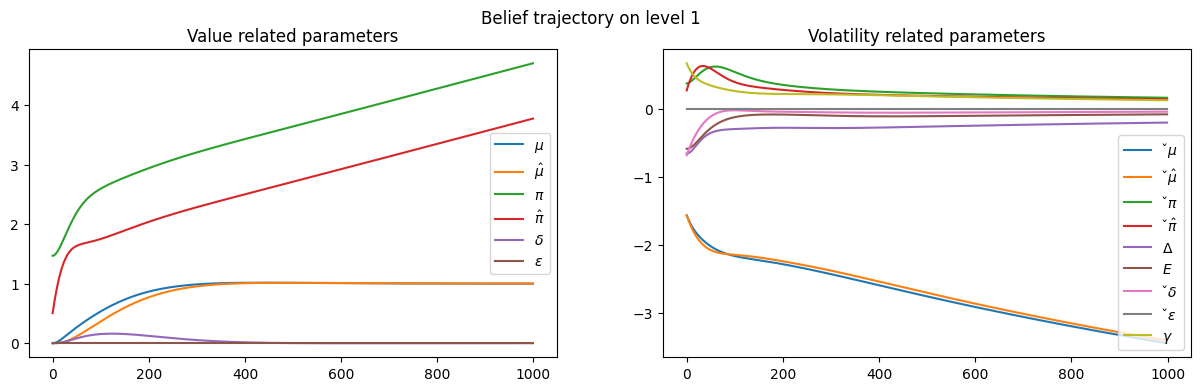

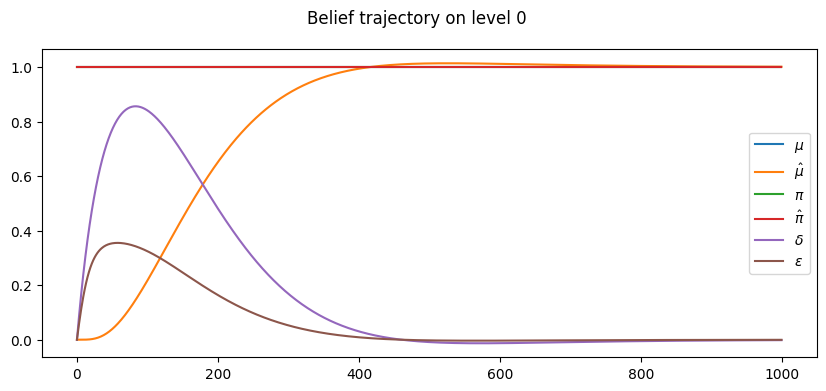

In [30]:
# @title
for level in attributes.keys():
    # Plot
    if level != 0:
        plt.figure(figsize=(15, 4))
        plt.suptitle("Belief trajectory on level "+str(level))

        plt.subplot(121)
        plt.title("Value related parameters")
        plt.plot(attributes[level]["mean"],label=r"$\mu$")
        plt.plot(attributes[level]["expected_mean"],label=r"$\hat{\mu}$")
        plt.plot(attributes[level]["precision"],label=r"$\pi$")
        plt.plot(attributes[level]["expected_precision"],label=r"$\hat{\pi}$")
        plt.plot(attributes[level]["pe"],label=r"$\delta$")
        #plt.plot(np.full(len(attributes[level]["expected_mean"]),X[np.argmax(Y)]),label="Exact bayesian posterior")
        #plt.plot(attributes[level]["v"],label="v")
        plt.plot(attributes[level]["precision_weighted_pe"],label=r"$\varepsilon$")
        plt.legend()

        plt.subplot(122)
        plt.title("Volatility related parameters")
        plt.plot(attributes[level]["vol_mean"],label=r"$\check{\mu}$")
        plt.plot(attributes[level]["vol_expected_mean"],label=r"$\check{\hat{\mu}}$")
        plt.plot(attributes[level]["vol_precision"],label=r"$\check{\pi}$")
        plt.plot(attributes[level]["vol_expected_precision"],label=r"$\check{\hat{\pi}}$")
        plt.plot(attributes[level]["vope"],label=r"$\Delta$")
        plt.plot(attributes[level]["precision_weighted_vope"],label="$E$")
        plt.plot(attributes[level]["vol_pe"],label=r"$\check{\delta}$")
        plt.plot(attributes[level]["vol_precision_weighted_pe"],label=r"$\check{\varepsilon}$")
        plt.plot(attributes[level]["gamma"],label=r"$\gamma$")
        plt.legend()
    else:
        plt.figure(figsize=(10, 4))
        plt.suptitle("Belief trajectory on level "+str(level))
        plt.plot(attributes[level]["mean"],label=r"$\mu$")
        plt.plot(attributes[level]["expected_mean"],label=r"$\hat{\mu}$")
        plt.plot(attributes[level]["precision"],label=r"$\pi$")
        plt.plot(attributes[level]["expected_precision"],label=r"$\hat{\pi}$")
        plt.plot(attributes[level]["pe"],label=r"$\delta$")
        #plt.plot(np.full(len(attributes[level]["expected_mean"]),X[np.argmax(Y)]),label="Exact bayesian posterior")
        #plt.plot(attributes[level]["v"],label="v")
        plt.plot(attributes[level]["precision_weighted_pe"],label=r"$\varepsilon$")
        plt.legend()

In [31]:
np.argmax(attributes[0]["precision_weighted_pe"])
np.argmax(attributes[0]["pe"])

np.int64(83)

In [32]:
# @title Print values
for level in attributes.keys():
    print("LEVEL "+str(level))
    print()
    print("---Starting points---")
    print("Mean: "+str(attributes[level]["mean"][0]))
    print("exp Mean: "+str(attributes[level]["expected_mean"][0]))
    print("Precision: "+str(attributes[level]["precision"][0]))
    print("exp Precision: "+str(attributes[level]["expected_precision"][0]))
    print("PE: "+str(attributes[level]["pe"][0]))
    print("PwPE: "+str(attributes[level]["precision_weighted_pe"][0]))
    if level != 0:
        print("vol Mean: "+str(attributes[level]["vol_mean"][0]))
        print("vol exp Mean: "+str(attributes[level]["vol_expected_mean"][0]))
        print("vol Precision: "+str(attributes[level]["vol_precision"][0]))
        print("vol exp Precision: "+str(attributes[level]["vol_expected_precision"][0]))
        print("vol PE: "+str(attributes[level]["vol_pe"][0]))
        print("vol PwPE: "+str(attributes[level]["vol_precision_weighted_pe"][0]))
        print("VOPE: "+str(attributes[level]["vope"][0]))
        print("PwVOPE: "+str(attributes[level]["precision_weighted_vope"][0]))
        print("p1: "+str(attributes[level]["p1"][0]))
        print("vol p1: "+str(attributes[level]["vol_p1"][0]))
        print("p2: "+str(attributes[level]["p2"][0]))
        print("v: "+str(attributes[level]["v"][0]))
        print("gamma: "+str(attributes[level]["gamma"][0]))
    print("--------------------")
    print()

    print("---Max / Min---")
    print("Mean: "+str(attributes[level]["mean"][np.argmax(attributes[level]["mean"])])+" "+str(attributes[level]["mean"][np.argmin(attributes[level]["mean"])]))
    print("exp Mean: "+str(attributes[level]["expected_mean"][np.argmax(attributes[level]["expected_mean"])])+" "+str(attributes[level]["expected_mean"][np.argmin(attributes[level]["expected_mean"])]))
    print("Precision: "+str(attributes[level]["precision"][np.argmax(attributes[level]["precision"])])+" "+str(attributes[level]["precision"][np.argmin(attributes[level]["precision"])]))
    print("exp Precision: "+str(attributes[level]["expected_precision"][np.argmax(attributes[level]["expected_precision"])])+" "+str(attributes[level]["expected_precision"][np.argmin(attributes[level]["expected_precision"])]))
    print("PE: "+str(attributes[level]["pe"][np.argmax(attributes[level]["pe"])])+" "+str(attributes[level]["pe"][np.argmin(attributes[level]["pe"])]))
    print("PwPE: "+str(attributes[level]["precision_weighted_pe"][np.argmax(attributes[level]["precision_weighted_pe"])])+" "+str(attributes[level]["precision_weighted_pe"][np.argmin(attributes[level]["precision_weighted_pe"])]))
    if level != 0:
      print("vol Mean: "+str(attributes[level]["vol_mean"][np.argmax(attributes[level]["vol_mean"])])+" "+str(attributes[level]["vol_mean"][np.argmin(attributes[level]["vol_mean"])]))
      print("vol exp Mean: "+str(attributes[level]["vol_expected_mean"][np.argmax(attributes[level]["vol_expected_mean"])])+" "+str(attributes[level]["vol_expected_mean"][np.argmin(attributes[level]["vol_expected_mean"])]))
      print("vol Precision: "+str(attributes[level]["vol_precision"][np.argmax(attributes[level]["vol_precision"])])+" "+str(attributes[level]["vol_precision"][np.argmin(attributes[level]["vol_precision"])]))
      print("vol exp Precision: "+str(attributes[level]["vol_expected_precision"][np.argmax(attributes[level]["vol_expected_precision"])])+" "+str(attributes[level]["vol_expected_precision"][np.argmin(attributes[level]["vol_expected_precision"])]))
      print("vol PE: "+str(attributes[level]["vol_pe"][np.argmax(attributes[level]["vol_pe"])])+" "+str(attributes[level]["vol_pe"][np.argmin(attributes[level]["vol_pe"])]))
      print("vol PwPE: "+str(attributes[level]["vol_precision_weighted_pe"][np.argmax(attributes[level]["vol_precision_weighted_pe"])])+" "+str(attributes[level]["vol_precision_weighted_pe"][np.argmin(attributes[level]["vol_precision_weighted_pe"])]))
      print("VOPE: "+str(attributes[level]["vope"][np.argmax(attributes[level]["vope"])])+" "+str(attributes[level]["vope"][np.argmin(attributes[level]["vope"])]))
      print("PwVOPE: "+str(attributes[level]["precision_weighted_vope"][np.argmax(attributes[level]["precision_weighted_vope"])])+" "+str(attributes[level]["precision_weighted_vope"][np.argmin(attributes[level]["precision_weighted_vope"])]))
      print("p1: "+str(attributes[level]["p1"][np.argmax(attributes[level]["p1"])])+" "+str(attributes[level]["p1"][np.argmin(attributes[level]["p1"])]))
      print("vol p1: "+str(attributes[level]["vol_p1"][np.argmax(attributes[level]["vol_p1"])])+" "+str(attributes[level]["vol_p1"][np.argmin(attributes[level]["vol_p1"])]))
      print("p2: "+str(attributes[level]["p2"][np.argmax(attributes[level]["p2"])])+" "+str(attributes[level]["p2"][np.argmin(attributes[level]["p2"])]))
      print("v: "+str(attributes[level]["v"][np.argmax(attributes[level]["v"])])+" "+str(attributes[level]["v"][np.argmin(attributes[level]["v"])]))
      print("gamma: "+str(attributes[level]["gamma"][np.argmax(attributes[level]["gamma"])])+" "+str(attributes[level]["gamma"][np.argmin(attributes[level]["gamma"])]))
    print("--------------------")
    print()

    print("---Actual end points---")
    print("Mean: "+str(attributes[level]["mean"][-1]))
    print("exp Mean: "+str(attributes[level]["expected_mean"][-1]))
    print("Precision: "+str(attributes[level]["precision"][-1]))
    print("exp Precision: "+str(attributes[level]["expected_precision"][-1]))
    print("PE: "+str(attributes[level]["pe"][-1]))
    print("PwPE: "+str(attributes[level]["precision_weighted_pe"][-1]))
    if level != 0:
        print("vol Mean: "+str(attributes[level]["vol_mean"][-1]))
        print("vol exp Mean: "+str(attributes[level]["vol_expected_mean"][-1]))
        print("vol Precision: "+str(attributes[level]["vol_precision"][-1]))
        print("vol exp Precision: "+str(attributes[level]["vol_expected_precision"][-1]))
        print("vol PE: "+str(attributes[level]["vol_pe"][-1]))
        print("vol PwPE: "+str(attributes[level]["vol_precision_weighted_pe"][-1]))
        print("VOPE: "+str(attributes[level]["vope"][-1]))
        print("PwVOPE: "+str(attributes[level]["precision_weighted_vope"][-1]))
        print("p1: "+str(attributes[level]["p1"][-1]))
        print("vol p1: "+str(attributes[level]["vol_p1"][-1]))
        print("p2: "+str(attributes[level]["p2"][-1]))
        print("v: "+str(attributes[level]["v"][-1]))
        print("gamma: "+str(attributes[level]["gamma"][-1]))
    print("--------------------")
    print()
    print("---Equilibirum points from gHGF---")
    #print("Exact bayesian posterior: "+str(X[np.argmax(Y)]))
    print("Mean: "+str(hgf.node_trajectories[level]["mean"][-2]))
    print("Precision: "+str(hgf.node_trajectories[level]["precision"][-2]))
    print("exp Mean: "+str(hgf.node_trajectories[level]["expected_mean"][-1]))
    print("exp Precision: "+str(hgf.node_trajectories[level]["expected_precision"][-1]))
    pe = hgf.node_trajectories[level]["mean"][-2] - hgf.node_trajectories[level]["expected_mean"][-2]
    print("PE: "+str(pe))
    if level != 0 and level < hgf.n_nodes -1:
        print("PwPE: "+str(pe * hgf.node_trajectories[level]["expected_precision"][-1] / hgf.node_trajectories[level+1]["precision"][-2]))
        print("vol exp Mean: "+str(hgf.node_trajectories[level+1]["expected_mean"][-1]))
        print("vol Mean: "+str(hgf.node_trajectories[level+1]["mean"][-2]))
        print("vol Precision: "+str(hgf.node_trajectories[level+1]["precision"][-2]))
        print("vol exp Precision: "+str(hgf.node_trajectories[level+1]["expected_precision"][-1]))
        print("vol PE: "+str(hgf.node_trajectories[level+1]["mean"][-2] - hgf.node_trajectories[level+1]["expected_mean"][-1]))
    print("--------------------")
    print()

LEVEL 1

---Starting points---
Mean: 3.655883119790815e-05
exp Mean: 3.655883119790815e-05
Precision: 1.4691228866577148
exp Precision: 0.5044788718223572
PE: -7.79301772126928e-05
PwPE: 0.0
vol Mean: -1.5675957202911377
vol exp Mean: -1.5675957202911377
vol Precision: 0.3756113350391388
vol exp Precision: 0.273050457239151
vol PE: -0.6806781888008118
vol PwPE: 0.0
VOPE: -0.6566122174263
PwVOPE: -0.5872948169708252
p1: -0.9646440148353577
vol p1: -0.10256087779998779
p2: 0.10520704090595245
v: 0.208545982837677
gamma: 0.6719174385070801
--------------------

---Max / Min---
Mean: 1.0160938951249079 3.655883119790815e-05
exp Mean: 1.0149820530248914 3.655883119790815e-05
Precision: 4.703412055969238 1.4691228866577148
exp Precision: 3.7741329542886946 0.5044788718223572
PE: 0.16006210729890974 -0.0016159942869516356
PwPE: 0.0 0.0
vol Mean: -1.5675957202911377 -3.449206665429602
vol exp Mean: -1.5675957202911377 -3.4107860255651605
vol Precision: 0.6238695879984432 0.16444609632338644
vo

mean_prior 3.655883119790815e-05
mean_evidence 1.0
variance_prior 1.982243570256261
variance_evidence 1.0
phi max 0.7636655765192488 @ 281
phi end 0.6646839024160088
pe_u max 0.5572623551883314 @ 127
pe_u end 0.33452345137055184
pe_p max 0.37226524876694234 @ 344
pe_p end 0.3356724537521496



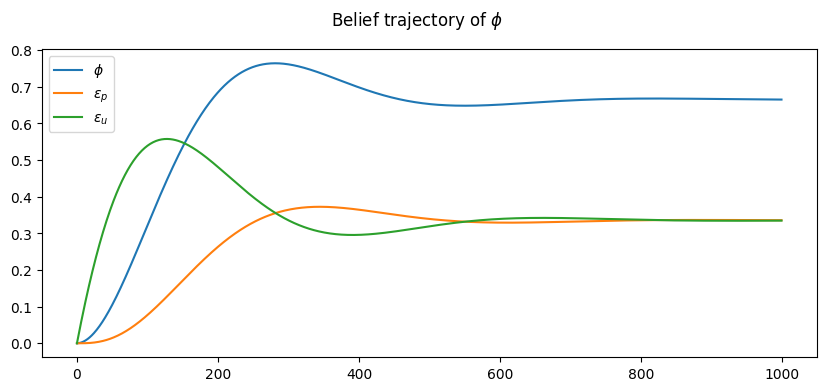

In [33]:
# @title PC model - inferring phi
duration_sec = 10
time_resolution = 0.01

mean_prior = attributes[1]["mean"][0]
mean_evidence = attributes[0]["mean"][0] # = 1

variance_prior = 1/attributes[1]["expected_precision"][0]
variance_evidence = 1/attributes[0]["expected_precision"][0]

plot_bogacz_ex2(duration_sec=duration_sec, time_resolution=time_resolution,mean_prior=mean_prior, variance_prior=variance_prior, mean_evidence=mean_evidence, variance_evidence=variance_evidence)
